<a href="https://colab.research.google.com/github/romanotancredi/equity-investment-research-portfolio/blob/main/04_regional_performance_attribution.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# 🌍 Phase 4 — Regional Performance Contribution & Attribution

## Investment Objective

Investigate the drivers of benchmark-relative performance
for a hypothetical global equity portfolio.

### Portfolio
- 60% VTI — US Equities
- 30% VEA — Developed Markets ex-US
- 10% VWO — Emerging Markets

### Benchmark
Vanguard Total World Stock ETF (VT)

### Methodology
- Daily portfolio return contributions
- Regional ETF returns relative to VT
- Arithmetic active return decomposition
- Annual analysis of regional contributions
- Assessment of regional allocation hypotheses

### Important Limitation
This is not a formal Brinson attribution because
historical regional benchmark weights are not yet included.


In [1]:

# ---------------------------------------------------------
# PHASE 4 - STEP 1: LOAD DATA AND CALCULATE CONTRIBUTIONS
# ---------------------------------------------------------

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the same ETF dataset used in previous phases.
data_url = (
    "https://raw.githubusercontent.com/romanotancredi/"
    "equity-investment-research-portfolio/refs/heads/main/"
    "01-equity-performance-and-risk/data/etf_prices.csv"
)

# Read ETF prices and convert the Date column into an index.
prices = pd.read_csv(
    data_url,
    index_col="Date",
    parse_dates=["Date"]
)

# Sort observations chronologically.
prices = prices[["VTI", "VEA", "VWO", "VT"]].sort_index()

# Calculate daily ETF returns.
# dropna() removes the first unavailable return.
daily_returns = prices.pct_change().dropna()

# Define the constant target weights.
weights = pd.Series({
    "VTI": 0.60,
    "VEA": 0.30,
    "VWO": 0.10
})

# Select only the three portfolio ETFs.
regional_returns = daily_returns[weights.index]

# Multiply each ETF's return by its portfolio weight.
#
# mul(weights, axis=1) performs column-wise multiplication.
#
# For example:
# VTI contribution = VTI daily return * 60%
#
# The result contains one contribution per ETF per day.

regional_contributions = regional_returns.mul(
    weights,
    axis=1
)

# Add the contributions across columns.
#
# sum(axis=1) calculates the sum across each row,
# producing the total portfolio return for each day.

portfolio_returns = regional_contributions.sum(axis=1)

# Extract VT benchmark returns.
benchmark_returns = daily_returns["VT"]

# Verify the contribution calculation against the
# weighted dot product used in Phase 2.

assert np.allclose(
    portfolio_returns,
    regional_returns.dot(weights)
)

display(regional_contributions.head())

,VTI,VEA,VWO
Date,,,
2020-01-03,-0.003819,-0.003647,-0.001779
2020-01-06,0.002050,0.001026,-0.000179
2020-01-07,-0.001423,-0.000477,-0.000045
2020-01-08,0.002962,0.000410,0.000448
2020-01-09,0.003747,0.001227,0.000513


In [2]:

# ---------------------------------------------------------
# PHASE 4 - STEP 2: DECOMPOSE DAILY ACTIVE RETURNS
# ---------------------------------------------------------

# Calculate each ETF's daily return relative to VT.
#
# sub(benchmark_returns, axis=0) subtracts the VT
# return for each date from each regional ETF return.

regional_relative_returns = regional_returns.sub(
    benchmark_returns,
    axis=0
)

# Multiply each regional relative return by its weight.
#
# This tells us how much each weighted ETF contributes
# to the portfolio's daily arithmetic active return.

regional_active_contributions = (
    regional_relative_returns.mul(weights, axis=1)
)

# Sum the contributions across regions.
active_returns = regional_active_contributions.sum(axis=1)

# Verify the decomposition is mathematically exact.
#
# np.allclose() checks whether two arrays are equal
# within a small numerical tolerance.

assert np.allclose(
    active_returns,
    portfolio_returns - benchmark_returns
)

# Calculate annualised arithmetic contributions.
#
# mean() calculates each ETF's average daily contribution.
# Multiplying by 252 annualises the arithmetic average.
#
# This is NOT a geometrically compounded attribution.

annualised_contributions = (
    regional_active_contributions.mean() * 252 * 100
)

print("Annualised arithmetic active contributions (pp):")
display(annualised_contributions.round(3))

print(
    "Total annualised arithmetic active return:",
    round(annualised_contributions.sum(), 3),
    "percentage points"
)

Annualised arithmetic active contributions (pp):


,0
VTI,1.353
VEA,-0.565
VWO,-0.544


Total annualised arithmetic active return: 0.243 percentage points


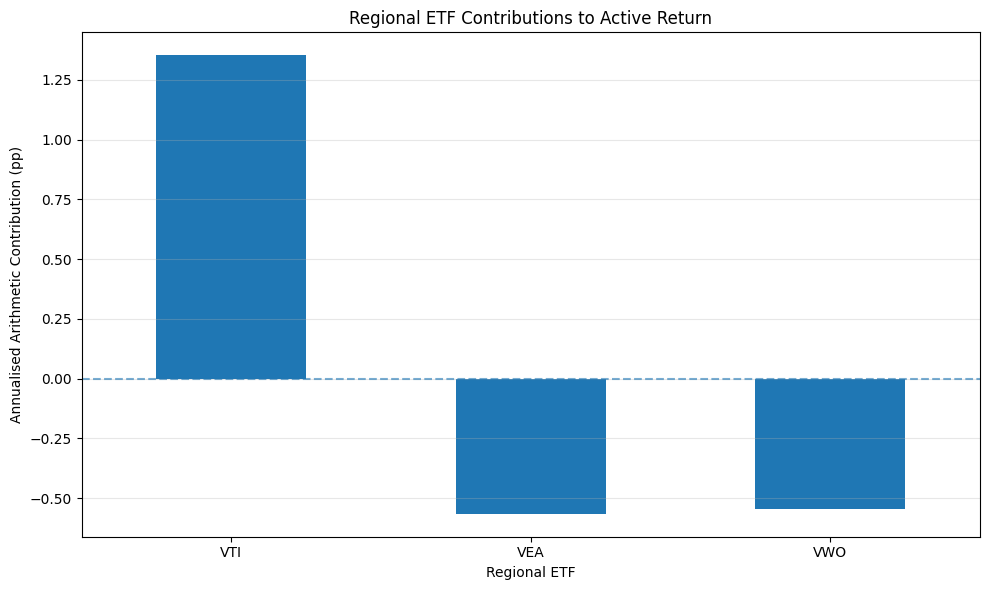

In [5]:

# ---------------------------------------------------------
# PHASE 4 - STEP 3: VISUALISE REGIONAL CONTRIBUTIONS
# ---------------------------------------------------------

# Create a new bar chart.
plt.figure(figsize=(10, 6))

# Plot annualised arithmetic active contributions.
#
# plot(kind="bar") produces one bar per regional ETF.

annualised_contributions.plot(kind="bar")

# Add a reference line at zero.
# Positive bars indicate positive contributions
# to arithmetic benchmark-relative returns.

plt.axhline(0, linestyle="--", alpha=0.5)

plt.title("Regional ETF Contributions to Active Return")
plt.xlabel("Regional ETF")
plt.ylabel("Annualised Arithmetic Contribution (pp)")

# Rotate labels to make them easier to read.
plt.xticks(rotation=0)

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [7]:

# ---------------------------------------------------------
# PHASE 4 - STEP 4: COMPOUNDED ANNUAL ACTIVE CONTRIBUTIONS
# ---------------------------------------------------------

# OBJECTIVE:
# Calculate the compounded annual portfolio return,
# benchmark return and linked regional active contributions.
#
# Unlike simply summing daily active contributions,
# geometric linking accounts for the compounding of returns.
#
# The linked regional contributions will reconcile exactly
# to the difference between compounded annual returns.


# ---------------------------------------------------------
# STEP 4A: CALCULATE COMPOUNDED ANNUAL RETURNS
# ---------------------------------------------------------

# Combine portfolio and benchmark daily returns.
#
# pd.DataFrame() creates a table with one row per date.

returns = pd.DataFrame({
    "Portfolio": portfolio_returns,
    "Benchmark": benchmark_returns
})

# Group observations by calendar year.
#
# index.year extracts the year from each trading date.
#
# (1 + returns) converts daily returns into growth factors.
# prod() multiplies growth factors within each year.
# Subtracting 1 gives the compounded annual return.

yearly_returns = (
    (1 + returns)
    .groupby(returns.index.year)
    .prod()
    - 1
)

# Calculate the annual compounded return difference.
#
# This is expressed in decimal terms at this stage.

yearly_returns["Active Difference"] = (
    yearly_returns["Portfolio"]
    - yearly_returns["Benchmark"]
)


# ---------------------------------------------------------
# STEP 4B: GEOMETRICALLY LINK REGIONAL CONTRIBUTIONS
# ---------------------------------------------------------

# We will calculate contributions separately for each year.
#
# This ensures that compounding restarts at the beginning
# of every calendar year.

yearly_linked_results = []

for year, annual_data in returns.groupby(returns.index.year):

    # Extract the portfolio and benchmark daily returns
    # belonging to the current calendar year.

    rp = annual_data["Portfolio"]
    rb = annual_data["Benchmark"]

    # Convert daily returns into growth factors.
    #
    # Example: +2% becomes 1.02.

    portfolio_growth = 1 + rp
    benchmark_growth = 1 + rb

    # Calculate benchmark growth BEFORE each observation.
    #
    # cumprod() compounds returns chronologically.
    # shift(1) excludes the current day's growth factor.
    # fillna(1) sets the first day's prior growth to 1.

    previous_benchmark_growth = (
        benchmark_growth.cumprod().shift(1).fillna(1.0)
    )

    # Calculate portfolio growth AFTER each observation.
    #
    # iloc[::-1] reverses the observation order.
    # cumprod() then calculates products backwards.
    # shift(1) excludes the current observation.
    # Reversing again restores chronological order.

    future_portfolio_growth = (
        portfolio_growth.iloc[::-1]
        .cumprod()
        .shift(1)
        .fillna(1.0)
        .iloc[::-1]
    )

    # Construct the geometric linking factor.
    #
    # It accounts for:
    # 1. Benchmark growth before the daily contribution
    # 2. Portfolio growth after the daily contribution

    linking_factor = (
        previous_benchmark_growth
        * future_portfolio_growth
    )

    # Select daily regional active contributions
    # for the current calendar year.
    #
    # These were calculated in Step 2.

    annual_contributions = (
        regional_active_contributions.loc[annual_data.index]
    )

    # Multiply daily contributions by the linking factor.
    #
    # mul(..., axis=0) applies the appropriate daily
    # linking factor to every regional ETF contribution.

    linked_contributions = annual_contributions.mul(
        linking_factor,
        axis=0
    )

    # Sum the geometrically linked contributions
    # for each regional ETF over the current year.
    #
    # These sums now reconcile to the compounded
    # annual portfolio-minus-benchmark return difference.

    annual_linked_contribution = linked_contributions.sum()

    # Assign the calendar year to the resulting Series.

    annual_linked_contribution.name = year

    # Store the result for later combination.

    yearly_linked_results.append(annual_linked_contribution)


# Combine all annual results into a DataFrame.
#
# Each row represents a year.
# Each column represents a regional ETF.

yearly_contributions = pd.DataFrame(yearly_linked_results)

# Calculate the total contribution across regions.

yearly_contributions["Total"] = (
    yearly_contributions.sum(axis=1)
)


# ---------------------------------------------------------
# STEP 4C: VALIDATE THE RESULTS
# ---------------------------------------------------------

# Verify that linked regional contributions reconcile
# to the actual compounded annual return difference.
#
# np.allclose() checks numerical equality within
# a small tolerance to account for floating-point errors.

assert np.allclose(
    yearly_contributions["Total"].to_numpy(),
    yearly_returns["Active Difference"].to_numpy()
), "Error: Annual contributions do not reconcile!"


# ---------------------------------------------------------
# STEP 4D: DISPLAY RESULTS
# ---------------------------------------------------------

# Multiply by 100 to express returns and contributions
# in percentages or percentage points.

print("Compounded Annual Portfolio Returns (%):")
display((yearly_returns * 100).round(2))

print("Linked Regional Active Contributions (pp):")
display((yearly_contributions * 100).round(2))


Compounded Annual Portfolio Returns (%):


,Portfolio,Benchmark,Active Difference
Date,,,
2020,16.11,15.42,0.69
2021,18.87,18.27,0.60
2022,-17.93,-18.00,0.08
2023,21.94,22.02,-0.08
2024,16.07,16.49,-0.43
2025,23.33,22.43,0.89
2026,11.20,11.06,0.14


Linked Regional Active Contributions (pp):


,VTI,VEA,VWO,Total
2020,2.84,-1.95,-0.20,0.69
2021,4.36,-2.00,-1.76,0.60
2022,-0.86,0.85,0.08,0.08
2023,2.42,-1.20,-1.30,-0.08
2024,4.30,-4.18,-0.54,-0.43
2025,-3.22,3.74,0.37,0.89
2026,0.47,0.41,-0.75,0.14


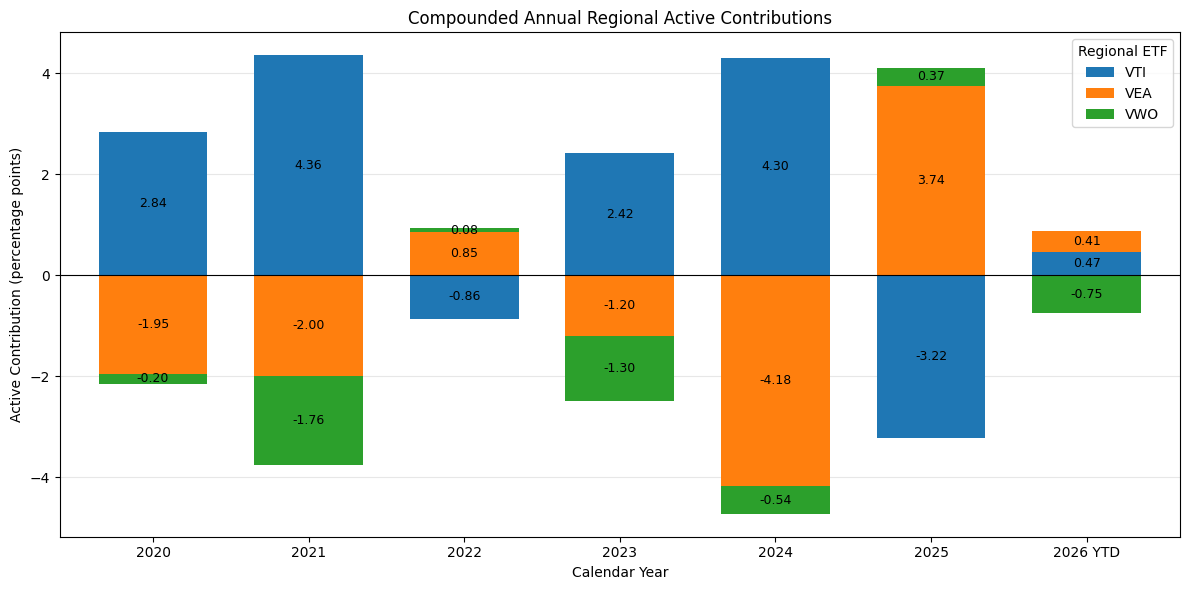

In [9]:

# ---------------------------------------------------------
# PHASE 4 - STEP 5: COMPOUNDED ANNUAL REGIONAL CONTRIBUTIONS
# ---------------------------------------------------------

# Retrieve geometrically linked annual active contributions.
# These were calculated in Step 4 and already account
# for compounding across daily return observations.
#
# Multiply by 100 to convert contributions into
# percentage points.

chart_data = yearly_contributions[["VTI", "VEA", "VWO"]] * 100

# Create a stacked bar chart.
# Each year has one bar containing three regional contributions.

ax = chart_data.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6),
    width=0.7
)

# Add numerical contribution labels to each bar segment.
#
# ax.containers contains the individual bar groups
# created for VTI, VEA and VWO.
#
# bar_label() displays the value of each segment.
# label_type="center" places the value inside the segment.

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f",
        label_type="center",
        fontsize=9
    )

# Add a horizontal line at zero.
ax.axhline(0, color="black", linewidth=0.8)

# Format the calendar years.
year_labels = [str(year) for year in chart_data.index]

# Identify 2026 as a partial year.
year_labels[-1] += " YTD"

ax.set_xticklabels(year_labels, rotation=0)

# Add chart title and labels.
ax.set_title("Compounded Annual Regional Active Contributions")
ax.set_xlabel("Calendar Year")
ax.set_ylabel("Active Contribution (percentage points)")

# Add a legend identifying each ETF.
ax.legend(title="Regional ETF")

# Add a light grid.
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

# Adjust layout and display the chart.
plt.tight_layout()
plt.show()


## 📊 Key Findings & Investment Interpretation

### Regional Performance Contributions

The hypothetical global equity portfolio outperformed the VT
benchmark over the observation period, with US equities (VTI)
representing the largest positive contributor to active returns.

Developed markets ex-US (VEA) and emerging markets (VWO)
contributed negatively to benchmark-relative performance.

### Performance Across Market Environments

Regional contributions varied throughout the observation period.
Despite its positive overall contribution, VTI detracted from
relative performance in 2022 and 2025.

This highlights how regional exposures can contribute differently
to portfolio performance depending on market conditions.

### Attribution Methodology

Daily regional active contributions were geometrically linked
to reconcile with the difference between compounded annual
portfolio and benchmark returns.

However, these results represent regional ETF contributions
rather than formal Brinson allocation or selection effects.

### Investment Implications

While US equity exposure contributed positively to historical
relative returns, further analysis of benchmark regional weights
is required to determine whether active allocation decisions
were responsible for the outperformance.

A positive contribution from VTI does not necessarily imply
that the portfolio was overweight US equities relative to VT.

### Conclusion

The analysis identifies the regional exposures associated with
historical benchmark-relative performance but does not establish
whether the portfolio's allocation decisions generated persistent
value.

The next stage will investigate allocation and selection effects
using a formal performance attribution framework.
